In [1]:
# Guia 09 Entrenamiento de modelos de Machine Learning - Smart Campus Analytics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Modelos
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Validación y clonación
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone

# Métricas
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Persistencia
import joblib

# Configuración global
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Estilo de gráficos
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print("Librerías importadas correctamente")
print(f"   - numpy: {np.__version__}")
print(f"   - pandas: {pd.__version__}")
print(f"   - scikit-learn: {__import__('sklearn').__version__}")
print(f"\nSemilla de reproducibilidad: {RANDOM_STATE}")

Librerías importadas correctamente
   - numpy: 2.4.6
   - pandas: 2.2.3
   - scikit-learn: 1.6.1

Semilla de reproducibilidad: 42


In [2]:
# ============================================================
# CELDA 2: Crear estructura de carpetas y ubicar el dataset
# ============================================================

import shutil
from pathlib import Path

BASE = Path('/content/proyecto_smart_campus')
(BASE / 'datos' / 'procesados').mkdir(parents=True, exist_ok=True)
(BASE / 'documentos').mkdir(parents=True, exist_ok=True)
(BASE / 'modelos').mkdir(parents=True, exist_ok=True)

NOMBRE_DATASET = 'dataset_limpio_Smart_Campus.csv'
RUTA_DATASET = BASE / 'datos' / 'procesados' / NOMBRE_DATASET

# Si el dataset aún no está en datos/procesados, se sube desde el equipo
if not RUTA_DATASET.exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(
            f"Coloca {NOMBRE_DATASET} en {RUTA_DATASET.parent}"
        )
    print(f"Selecciona el archivo {NOMBRE_DATASET}")
    subidos = files.upload()
    nombre_subido = list(subidos.keys())[0]
    shutil.move(str(Path('/content') / nombre_subido), str(RUTA_DATASET))


def mostrar_estructura(raiz):
    """Imprime el árbol de carpetas y archivos del proyecto."""
    print(f"{raiz.name}/")
    for ruta in sorted(raiz.rglob('*')):
        nivel = len(ruta.relative_to(raiz).parts)
        sufijo = '/' if ruta.is_dir() else ''
        print(f"{'    ' * nivel}{ruta.name}{sufijo}")


print("ESTRUCTURA DEL PROYECTO")
print("=" * 55)
mostrar_estructura(BASE)


Selecciona el archivo dataset_limpio_Smart_Campus.csv


Saving dataset_limpio_Smart_Campus.csv to dataset_limpio_Smart_Campus.csv
ESTRUCTURA DEL PROYECTO
proyecto_smart_campus/
    datos/
        procesados/
            dataset_limpio_Smart_Campus.csv
    documentos/
    modelos/


In [3]:
# ============================================================
# CELDA 3: Reconstruir dataset
# ============================================================

df_raw = pd.read_csv(RUTA_DATASET)

# Convertir la columna fecha a formato datetime
df_raw['fecha'] = pd.to_datetime(df_raw['fecha'])

# Agrupar a nivel diario para analizar la demanda global del Smart Campus
df = df_raw.groupby('fecha').agg(
    estudiantes_presentes=('estudiantes_presentes', 'sum'),
    horas_uso_promedio=('horas_uso', 'mean'),
    porcentaje_ocupacion_medio=('porcentaje_ocupacion', 'mean')
).reset_index()

# Ordenar cronológicamente por seguridad
df = df.sort_values('fecha').reset_index(drop=True)

# Extraer características temporales básicas
df['dia_semana'] = df['fecha'].dt.dayofweek
df['mes'] = df['fecha'].dt.month

# Feature engineering temporal
df["lag_1"] = df["estudiantes_presentes"].shift(1)
df["lag_7"] = df["estudiantes_presentes"].shift(7)
df["media_movil_7"] = df["estudiantes_presentes"].shift(1).rolling(7).mean()

# Eliminar NaN de los primeros días
df_modelo = df.dropna().copy()

print(f"Dataset reconstruido: {df_modelo.shape[0]} filas, {df_modelo.shape[1]} columnas")
print(f"Media estudiantes presentes: {df_modelo['estudiantes_presentes'].mean():,.2f}")
print(f"\nPrimeras 3 filas:")
print(df_modelo.head(3).to_string())


Dataset reconstruido: 174 filas, 9 columnas
Media estudiantes presentes: 1,221.74

Primeras 3 filas:
       fecha  estudiantes_presentes  horas_uso_promedio  porcentaje_ocupacion_medio  dia_semana  mes   lag_1   lag_7  media_movil_7
7 2026-01-22                   1219            2.385965                   67.905263           3    1  1166.0  1329.0    1151.571429
8 2026-01-23                   1340            2.412698                   69.985556           4    1  1219.0   812.0    1135.857143
9 2026-01-24                   1204            2.471698                   71.576792           5    1  1340.0  1315.0    1211.285714


In [4]:
# ============================================================
# CELDA 4: Definir X, y y split 80/20 cronológico
# ============================================================

features = [
    "dia_semana", "mes",
    "lag_1", "lag_7", "media_movil_7"
]

X = df_modelo[features]
y = df_modelo["estudiantes_presentes"]

# Split cronológico
corte = int(len(df_modelo) * 0.80)

X_train, X_test = X.iloc[:corte], X.iloc[corte:]
y_train, y_test = y.iloc[:corte], y.iloc[corte:]
fecha_test = df_modelo["fecha"].iloc[corte:]

print("SPLIT CRONOLÓGICO 80/20")
print("=" * 55)
print(f"Entrenamiento: {X_train.shape}")
print(f"Prueba:        {X_test.shape}")
print(f"Última fecha train: {df_modelo['fecha'].iloc[corte-1].date()}")
print(f"Primera fecha test: {df_modelo['fecha'].iloc[corte].date()}")
print(f"¿Test después de train? {df_modelo['fecha'].iloc[corte] > df_modelo['fecha'].iloc[corte-1]}")

SPLIT CRONOLÓGICO 80/20
Entrenamiento: (139, 5)
Prueba:        (35, 5)
Última fecha train: 2026-06-09
Primera fecha test: 2026-06-10
¿Test después de train? True


In [5]:
# ============================================================
# CELDA 5: Catálogo de modelos candidatos
# ============================================================

modelos = {
    "Baseline media":    DummyRegressor(strategy="mean"),
    "Regresión lineal":  LinearRegression(),
    "Árbol de decisión": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest":     RandomForestRegressor(random_state=RANDOM_STATE)
}

print("MODELOS EN EL CATÁLOGO")
print("=" * 55)
for i, nombre in enumerate(modelos.keys(), 1):
    print(f"  {i}. {nombre}")

MODELOS EN EL CATÁLOGO
  1. Baseline media
  2. Regresión lineal
  3. Árbol de decisión
  4. Random Forest


In [6]:
# ============================================================
# CELDA 6: Función de métricas y evaluación holdout
# ============================================================

import time


def metricas_regresion(y_real, y_pred):
    """Calcula MAE, RMSE y R²."""
    return {
        "MAE":  mean_absolute_error(y_real, y_pred),
        "RMSE": mean_squared_error(y_real, y_pred) ** 0.5,
        "R2":   r2_score(y_real, y_pred)
    }


def evaluar_holdout(nombre, estimador):
    """
    Entrena un modelo clonado, evalúa en train y test,
    y devuelve (modelo, fila_resultado, predicciones_test).
    """
    modelo = clone(estimador)
    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    tiempo_fit = time.perf_counter() - inicio

    pred_train = modelo.predict(X_train)
    pred_test  = modelo.predict(X_test)

    mt = metricas_regresion(y_train, pred_train)
    mp = metricas_regresion(y_test,  pred_test)

    fila = {
        "Modelo":     nombre,
        "MAE_train":  mt["MAE"],
        "MAE_test":   mp["MAE"],
        "RMSE_test":  mp["RMSE"],
        "R2_test":    mp["R2"],
        "Brecha_MAE": mp["MAE"] - mt["MAE"],
        "Tiempo_fit_s": tiempo_fit
    }

    return modelo, fila, pred_test


print("Funciones definidas correctamente")

Funciones definidas correctamente


In [7]:
# ============================================================
# CELDA 7: Entrenar y evaluar todos los modelos (holdout)
# ============================================================

resultados_holdout = []
modelos_entrenados = {}
predicciones       = {}

for nombre, estimador in modelos.items():
    modelo, fila, pred = evaluar_holdout(nombre, estimador)
    modelos_entrenados[nombre] = modelo
    predicciones[nombre]       = pred
    resultados_holdout.append(fila)

tabla_holdout = pd.DataFrame(resultados_holdout)

print("RESULTADOS EN HOLDOUT (sin ordenar)")
print("=" * 75)
print(tabla_holdout.round(2).to_string(index=False))

RESULTADOS EN HOLDOUT (sin ordenar)
           Modelo  MAE_train  MAE_test  RMSE_test  R2_test  Brecha_MAE  Tiempo_fit_s
   Baseline media     143.10    157.63     198.33    -0.00       14.53          0.00
 Regresión lineal     139.07    175.52     217.20    -0.20       36.45          0.02
Árbol de decisión       0.00    239.71     292.26    -1.17      239.71          0.00
    Random Forest      56.76    196.69     242.54    -0.50      139.94          0.19


In [8]:
# ============================================================
# CELDA 8: Ordenar por MAE_test y mejora vs baseline
# ============================================================

mae_baseline = tabla_holdout.loc[
    tabla_holdout["Modelo"] == "Baseline media", "MAE_test"
].iloc[0]

tabla_holdout["Mejora_vs_baseline_pct"] = (
    (mae_baseline - tabla_holdout["MAE_test"]) / mae_baseline * 100
)

tabla_holdout = tabla_holdout.sort_values("MAE_test").reset_index(drop=True)

print(f"MAE del baseline: {mae_baseline:,.2f}")
print("\nTABLA COMPARATIVA (ordenada por MAE_test)")
print("=" * 90)
print(tabla_holdout.round(2).to_string(index=False))

MAE del baseline: 157.63

TABLA COMPARATIVA (ordenada por MAE_test)
           Modelo  MAE_train  MAE_test  RMSE_test  R2_test  Brecha_MAE  Tiempo_fit_s  Mejora_vs_baseline_pct
   Baseline media     143.10    157.63     198.33    -0.00       14.53          0.00                    0.00
 Regresión lineal     139.07    175.52     217.20    -0.20       36.45          0.02                  -11.35
    Random Forest      56.76    196.69     242.54    -0.50      139.94          0.19                  -24.78
Árbol de decisión       0.00    239.71     292.26    -1.17      239.71          0.00                  -52.07


In [9]:
# ============================================================
# CELDA 9: Diagnóstico de sobreajuste (brecha train/test)
# ============================================================

print("DIAGNÓSTICO DE SOBREAJUSTE")
print("=" * 75)

for _, row in tabla_holdout.iterrows():
    nombre   = row["Modelo"]
    brecha   = row["Brecha_MAE"]
    mae_tr   = row["MAE_train"]

    if mae_tr < 1:
        señal = "(ROJO) Posible sobreajuste severo (MAE_train ≈ 0)"
    elif brecha > mae_tr * 2:
        señal = "(NARANJA) Posible sobreajuste (brecha > 2×MAE_train)"
    elif brecha < 0:
        señal = "(AMARILLO) Brecha negativa (test más fácil que train)"
    else:
        señal = "(VERDE) Brecha razonable"

    print(f"\n{nombre}")
    print(f"   MAE_train: {mae_tr:>8,.2f}")
    print(f"   MAE_test:  {row['MAE_test']:>8,.2f}")
    print(f"   Brecha:    {brecha:>8,.2f}")
    print(f"   → {señal}")

DIAGNÓSTICO DE SOBREAJUSTE

Baseline media
   MAE_train:   143.10
   MAE_test:    157.63
   Brecha:       14.53
   → (VERDE) Brecha razonable

Regresión lineal
   MAE_train:   139.07
   MAE_test:    175.52
   Brecha:       36.45
   → (VERDE) Brecha razonable

Random Forest
   MAE_train:    56.76
   MAE_test:    196.69
   Brecha:      139.94
   → (NARANJA) Posible sobreajuste (brecha > 2×MAE_train)

Árbol de decisión
   MAE_train:     0.00
   MAE_test:    239.71
   Brecha:      239.71
   → (ROJO) Posible sobreajuste severo (MAE_train ≈ 0)


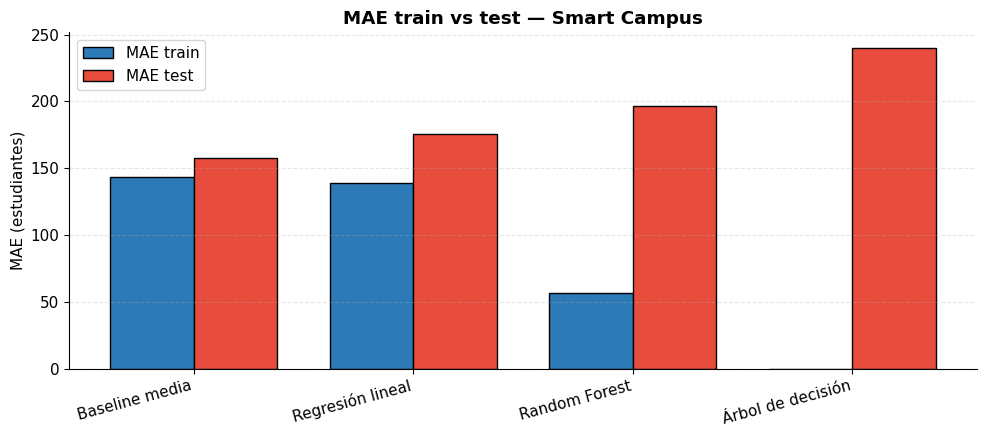

In [10]:
# ============================================================
# CELDA 10: Gráfico MAE train vs test por modelo
# ============================================================

graf_gap = tabla_holdout.sort_values("MAE_test")
x = np.arange(len(graf_gap))
ancho = 0.38

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - ancho / 2, graf_gap["MAE_train"], ancho,
       label="MAE train", color='#2c7bb6', edgecolor='black')
ax.bar(x + ancho / 2, graf_gap["MAE_test"], ancho,
       label="MAE test", color='#e74c3c', edgecolor='black')

ax.set_xticks(x)
ax.set_xticklabels(graf_gap["Modelo"], rotation=15, ha='right')
ax.set_ylabel("MAE (estudiantes)")
ax.set_title("MAE train vs test — Smart Campus", fontweight='bold')
ax.legend()
ax.grid(alpha=0.3, axis='y', linestyle='--')
plt.tight_layout()
plt.show()


In [11]:
# ============================================================
# CELDA 11: Crear TimeSeriesSplit y visualizar folds
# ============================================================

tscv = TimeSeriesSplit(n_splits=5)

print("FOLDS DE VALIDACIÓN TEMPORAL")
print("=" * 75)
print(f"{'Fold':<6}{'Train inicio':<14}{'Train fin':<14}{'Val inicio':<14}{'Val fin':<14}")

for fold, (idx_train, idx_val) in enumerate(tscv.split(X_train), 1):
    print(
        f"{fold:<6}"
        f"{idx_train[0]:<14}"
        f"{idx_train[-1]:<14}"
        f"{idx_val[0]:<14}"
        f"{idx_val[-1]:<14}"
    )

print(f"\nTotal de filas en X_train: {len(X_train)}")
print(f"Filas por fold de validación: ~{len(X_train) // (len(list(tscv.split(X_train))) + 1)}")

FOLDS DE VALIDACIÓN TEMPORAL
Fold  Train inicio  Train fin     Val inicio    Val fin       
1     0             23            24            46            
2     0             46            47            69            
3     0             69            70            92            
4     0             92            93            115           
5     0             115           116           138           

Total de filas en X_train: 139
Filas por fold de validación: ~23


In [12]:
# ============================================================
# CELDA 12: Función de validación temporal
# ============================================================

def validar_temporal(nombre, estimador):
    """Aplica TimeSeriesSplit a un estimador y devuelve métricas por fold."""
    filas = []

    for fold, (idx_tr, idx_val) in enumerate(tscv.split(X_train), 1):
        X_tr  = X_train.iloc[idx_tr]
        X_val = X_train.iloc[idx_val]
        y_tr  = y_train.iloc[idx_tr]
        y_val = y_train.iloc[idx_val]

        m = clone(estimador)
        m.fit(X_tr, y_tr)

        pred_tr  = m.predict(X_tr)
        pred_val = m.predict(X_val)

        filas.append({
            "Modelo":    nombre,
            "Fold":      fold,
            "MAE_train": mean_absolute_error(y_tr, pred_tr),
            "MAE_val":   mean_absolute_error(y_val, pred_val),
            "RMSE_val":  mean_squared_error(y_val, pred_val) ** 0.5,
            "R2_val":    r2_score(y_val, pred_val)
        })

    return pd.DataFrame(filas)


print("Función 'validar_temporal' definida correctamente")

Función 'validar_temporal' definida correctamente


In [13]:
# ============================================================
# CELDA 13: Ejecutar validación cruzada
# ============================================================

validaciones = []
for nombre, estimador in modelos.items():
    validaciones.append(validar_temporal(nombre, estimador))

df_cv = pd.concat(validaciones, ignore_index=True)

print("DETALLE DE VALIDACIÓN CRUZADA")
print("=" * 75)
print(df_cv.round(2).to_string(index=False))

DETALLE DE VALIDACIÓN CRUZADA
           Modelo  Fold  MAE_train  MAE_val  RMSE_val  R2_val
   Baseline media     1     139.21   142.29    178.46   -0.07
   Baseline media     2     140.94   136.24    178.88   -0.08
   Baseline media     3     137.52   126.71    156.34   -0.03
   Baseline media     4     134.91   189.45    213.70   -0.00
   Baseline media     5     145.70   131.29    161.68   -0.07
 Regresión lineal     1     135.03   141.61    173.25   -0.01
 Regresión lineal     2     138.54   185.30    217.52   -0.60
 Regresión lineal     3     136.54   125.51    155.29   -0.01
 Regresión lineal     4     133.48   176.71    207.08    0.06
 Regresión lineal     5     141.10   134.18    173.27   -0.23
Árbol de decisión     1       0.00   170.96    207.02   -0.44
Árbol de decisión     2       0.00   239.91    294.94   -1.94
Árbol de decisión     3       0.00   193.30    242.03   -1.46
Árbol de decisión     4       0.00   241.43    280.38   -0.72
Árbol de decisión     5       0.00   247

In [14]:
# ============================================================
# CELDA 14: Resumen por modelo (media y std)
# ============================================================

resumen_cv = (
    df_cv
    .groupby("Modelo")
    .agg(
        MAE_cv_media   = ("MAE_val",    "mean"),
        MAE_cv_std     = ("MAE_val",    "std"),
        RMSE_cv_media  = ("RMSE_val",   "mean"),
        R2_cv_media    = ("R2_val",     "mean")
    )
    .reset_index()
    .sort_values("MAE_cv_media")
    .reset_index(drop=True)
)

print("RESUMEN DE VALIDACIÓN CRUZADA")
print("=" * 85)
print(resumen_cv.round(2).to_string(index=False))

RESUMEN DE VALIDACIÓN CRUZADA
           Modelo  MAE_cv_media  MAE_cv_std  RMSE_cv_media  R2_cv_media
   Baseline media        145.20       25.41         177.81        -0.05
 Regresión lineal        152.66       26.67         185.28        -0.16
    Random Forest        155.16       25.55         192.17        -0.25
Árbol de decisión        218.62       34.35         265.40        -1.46


In [15]:
# ============================================================
# CELDA 15: Integrar holdout + CV y marcar candidatos
# ============================================================

comparacion = tabla_holdout.merge(resumen_cv, on="Modelo", how="left")
comparacion = comparacion.sort_values("MAE_test").reset_index(drop=True)

# Criterios de selección
comparacion["Supera_baseline"] = comparacion["Mejora_vs_baseline_pct"] > 0
comparacion["CV_estable"]      = (
    comparacion["MAE_cv_std"] < comparacion["MAE_cv_media"] * 0.25
)

columnas_mostrar = [
    "Modelo", "MAE_test", "Mejora_vs_baseline_pct",
    "MAE_cv_media", "MAE_cv_std", "Brecha_MAE",
    "Supera_baseline", "CV_estable"
]

print("TABLA COMPARATIVA INTEGRADA")
print("=" * 110)
print(comparacion[columnas_mostrar].round(2).to_string(index=False))

TABLA COMPARATIVA INTEGRADA
           Modelo  MAE_test  Mejora_vs_baseline_pct  MAE_cv_media  MAE_cv_std  Brecha_MAE  Supera_baseline  CV_estable
   Baseline media    157.63                    0.00        145.20       25.41       14.53            False        True
 Regresión lineal    175.52                  -11.35        152.66       26.67       36.45            False        True
    Random Forest    196.69                  -24.78        155.16       25.55      139.94            False        True
Árbol de decisión    239.71                  -52.07        218.62       34.35      239.71            False        True


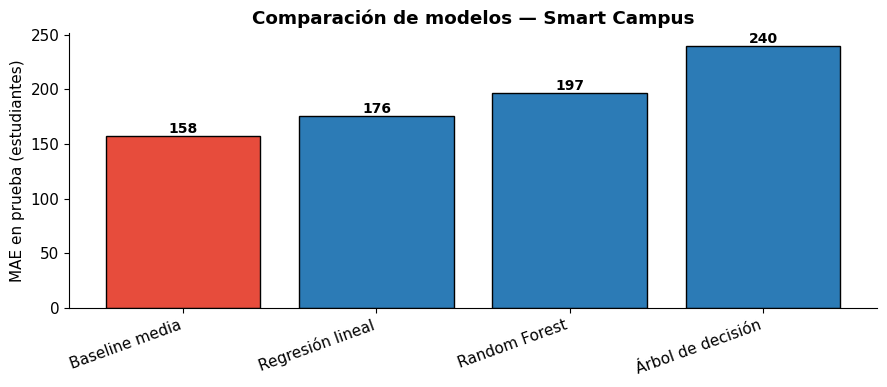

In [16]:
# ============================================================
# CELDA 16: Gráfico de barras MAE_test por modelo
# ============================================================

graf = comparacion.sort_values("MAE_test")

fig, ax = plt.subplots(figsize=(9, 4))
colores = ['#e74c3c' if m == "Baseline media" else '#2c7bb6'
           for m in graf["Modelo"]]

bars = ax.bar(graf["Modelo"], graf["MAE_test"], color=colores, edgecolor='black')

# Etiquetas de valor sobre cada barra
for bar, val in zip(bars, graf["MAE_test"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{val:,.0f}", ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylabel("MAE en prueba (estudiantes)")
ax.set_title("Comparación de modelos — Smart Campus", fontweight='bold')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

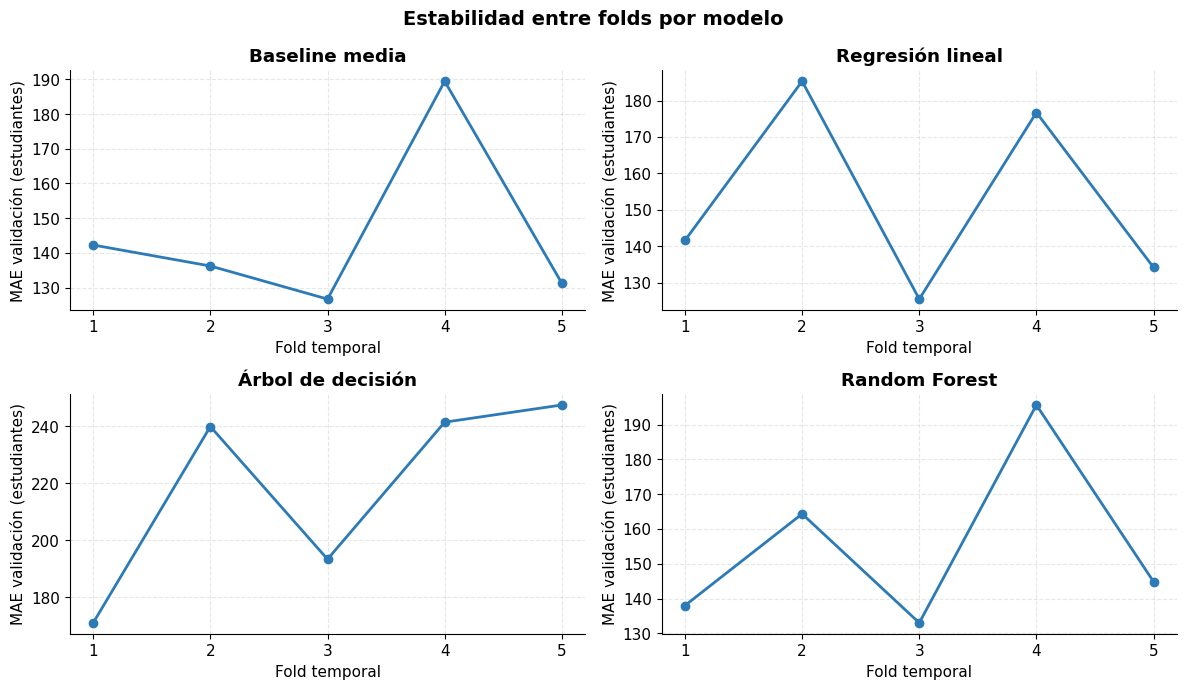

In [17]:
# ============================================================
# CELDA 17: Estabilidad entre folds (una gráfica por modelo)
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes = axes.flatten()

for i, nombre in enumerate(df_cv["Modelo"].unique()):
    temp = df_cv[df_cv["Modelo"] == nombre]
    axes[i].plot(temp["Fold"], temp["MAE_val"],
                 marker='o', linewidth=2, color='#2c7bb6')
    axes[i].set_title(nombre, fontweight='bold')
    axes[i].set_xlabel("Fold temporal")
    axes[i].set_ylabel("MAE validación (estudiantes)")
    axes[i].grid(alpha=0.3, linestyle='--')
    axes[i].set_xticks(temp["Fold"].tolist())

plt.suptitle("Estabilidad entre folds por modelo", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# CELDA 18: Seleccionar candidato provisional
# ============================================================

candidato_ordenado = comparacion.sort_values("MAE_test")

nombre_candidato = candidato_ordenado.iloc[0]["Modelo"]
modelo_candidato = modelos_entrenados[nombre_candidato]
pred_candidato   = predicciones[nombre_candidato]

print("CANDIDATO PROVISIONAL")
print("=" * 55)
print(f"  Modelo: {nombre_candidato}")
print(f"  MAE_test: {candidato_ordenado.iloc[0]['MAE_test']:,.2f}")
print(f"  RMSE_test: {candidato_ordenado.iloc[0]['RMSE_test']:,.2f}")
print(f"  R²_test: {candidato_ordenado.iloc[0]['R2_test']:.4f}")
print(f"  Mejor MAE en validación cruzada: {resumen_cv.iloc[0]['Modelo']}")

print(f"\nModelos que superan al baseline:")
superan = comparacion[comparacion["Supera_baseline"]]
if superan.empty:
    print("  Ninguno")
for _, row in superan.iterrows():
    print(f"  - {row['Modelo']}: {row['MAE_test']:,.2f}")


CANDIDATO PROVISIONAL
  Modelo: Baseline media
  MAE_test: 157.63
  RMSE_test: 198.33
  R²_test: -0.0009
  Mejor MAE en validación cruzada: Baseline media

Modelos que superan al baseline:
  Ninguno


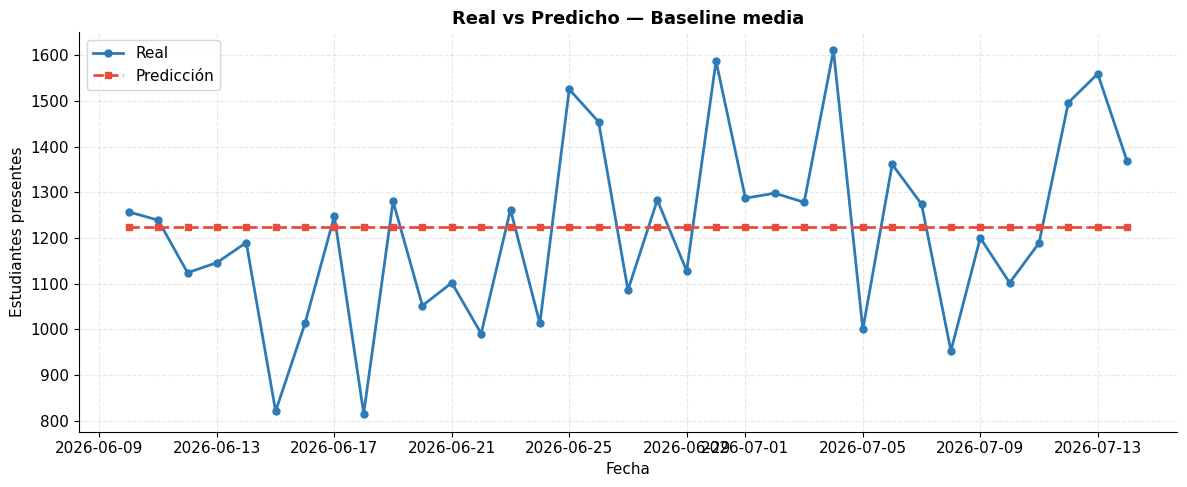

In [19]:
# ============================================================
# CELDA 19: Gráfico Real vs Predicho del candidato
# ============================================================

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(fecha_test, y_test.values, label="Real",
        color='#2c7bb6', marker='o', linewidth=2, markersize=5)
ax.plot(fecha_test, pred_candidato, label="Predicción",
        color='#e74c3c', marker='s', linewidth=2,
        markersize=5, linestyle='--')

ax.set_title(f"Real vs Predicho — {nombre_candidato}",
             fontsize=13, fontweight='bold')
ax.set_xlabel("Fecha")
ax.set_ylabel("Estudiantes presentes")
ax.legend(loc='upper left')
ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

In [20]:
# ============================================================
# CELDA 20: Top 5 errores más grandes del candidato
# ============================================================

errores = pd.DataFrame({
    "fecha":    fecha_test.values,
    "real":     y_test.values,
    "predicho": pred_candidato
})

errores["error"]     = errores["real"] - errores["predicho"]
errores["error_abs"] = errores["error"].abs()

print("ESTADÍSTICAS DE ERROR")
print("=" * 55)
print(f"  Error promedio:  {errores['error'].mean():,.2f}")
print(f"  Error mínimo:    {errores['error'].min():,.2f}")
print(f"  Error máximo:    {errores['error'].max():,.2f}")

print(f"\nTOP 5 ERRORES MÁS GRANDES")
print("=" * 75)
top5 = errores.nlargest(5, "error_abs").copy()
top5["fecha"] = top5["fecha"].dt.date
print(top5.round(2).to_string(index=False))

ESTADÍSTICAS DE ERROR
  Error promedio:  -6.04
  Error mínimo:    -406.95
  Error máximo:    387.05

TOP 5 ERRORES MÁS GRANDES
     fecha  real  predicho   error  error_abs
2026-06-18   816   1222.95 -406.95     406.95
2026-06-15   821   1222.95 -401.95     401.95
2026-07-04  1610   1222.95  387.05     387.05
2026-06-30  1587   1222.95  364.05     364.05
2026-07-13  1559   1222.95  336.05     336.05


In [21]:
# ============================================================
# CELDA 21: Interpretación de variables del candidato
# ============================================================

if hasattr(modelo_candidato, "coef_"):
    importancia = pd.DataFrame({
        "variable": features,
        "valor":    modelo_candidato.coef_
    }).sort_values("valor", key=lambda s: s.abs(), ascending=False)

    print(f"COEFICIENTES — {nombre_candidato}")
    print("=" * 65)
    print(importancia.round(4).to_string(index=False))
    print(f"\nIntercepto: {modelo_candidato.intercept_:,.2f}")

elif hasattr(modelo_candidato, "feature_importances_"):
    importancia = pd.DataFrame({
        "variable": features,
        "valor":    modelo_candidato.feature_importances_
    }).sort_values("valor", ascending=False)

    print(f"FEATURE IMPORTANCE — {nombre_candidato}")
    print("=" * 65)
    print(importancia.round(4).to_string(index=False))
    print(f"\nSuma de importancias: {importancia['valor'].sum():.4f}")

else:
    importancia = pd.DataFrame()
    print("El modelo no expone coeficientes ni importancias.")

El modelo no expone coeficientes ni importancias.


In [22]:
# ============================================================
# CELDA 22: Gráfico de importancia de variables
# ============================================================

if not importancia.empty:
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.barh(importancia["variable"], importancia["valor"].abs(),
            color='#2c7bb6', edgecolor='black')
    ax.set_xlabel("Magnitud de la contribución")
    ax.set_title(f"Importancia de variables — {nombre_candidato}",
                 fontweight='bold')
    ax.invert_yaxis()
    ax.grid(alpha=0.3, axis='x', linestyle='--')
    plt.tight_layout()
    plt.show()
else:
    print("Sin datos de importancia para graficar.")

Sin datos de importancia para graficar.


In [23]:
# ============================================================
# CELDA 23: Matriz de decisión técnica
# ============================================================

fila_cand = candidato_ordenado.iloc[0]
error_max = errores["error_abs"].max()
pct_error_max = error_max / y_test.mean() * 100

matriz = pd.DataFrame({
    "Criterio": [
        "Desempeño",
        "Generalización",
        "Estabilidad",
        "Interpretabilidad",
        "Costo",
        "Riesgo"
    ],
    "Pregunta": [
        "¿Supera claramente al baseline?",
        "¿La brecha train/test es razonable?",
        "¿Los folds son consistentes?",
        "¿Podemos explicar la salida?",
        "¿Tiempo y recursos adecuados?",
        "¿Errores graves en escenarios críticos?"
    ],
    "Valor observado": [
        "Es el baseline (referencia)" if nombre_candidato == "Baseline media"
        else f"{fila_cand['Mejora_vs_baseline_pct']:.1f}% mejora",
        f"Brecha {fila_cand['Brecha_MAE']:,.2f} estudiantes",
        f"Std {fila_cand['MAE_cv_std']:,.2f} estudiantes",
        "Coefs" if hasattr(modelo_candidato, "coef_")
        else "Feature importances" if hasattr(modelo_candidato, "feature_importances_")
        else "Predice la media de entrenamiento",
        f"{fila_cand['Tiempo_fit_s']:.3f} s de entrenamiento",
        f"Error máximo {error_max:,.0f} estudiantes ({pct_error_max:.0f}% de la media diaria)"
    ]
})

print("MATRIZ DE DECISIÓN TÉCNICA")
print("=" * 95)
print(matriz.to_string(index=False))


MATRIZ DE DECISIÓN TÉCNICA
         Criterio                                Pregunta                                       Valor observado
        Desempeño         ¿Supera claramente al baseline?                           Es el baseline (referencia)
   Generalización     ¿La brecha train/test es razonable?                              Brecha 14.53 estudiantes
      Estabilidad            ¿Los folds son consistentes?                                 Std 25.41 estudiantes
Interpretabilidad            ¿Podemos explicar la salida?                     Predice la media de entrenamiento
            Costo           ¿Tiempo y recursos adecuados?                              0.001 s de entrenamiento
           Riesgo ¿Errores graves en escenarios críticos? Error máximo 407 estudiantes (33% de la media diaria)


In [24]:
# ============================================================
# CELDA 24: Decisión final y justificación del modelo
# ============================================================

fila_cand = candidato_ordenado.iloc[0]
no_base = comparacion[comparacion["Modelo"] != "Baseline media"].sort_values("MAE_test")
mejor_no_base = no_base.iloc[0]
es_baseline = nombre_candidato == "Baseline media"
otros = comparacion[comparacion["Modelo"] != nombre_candidato]

print("DECISIÓN FINAL")
print("=" * 75)
print(f"Modelo elegido: {nombre_candidato}\n")

print("Por qué se elige:")
print(f"  1. Desempeño: MAE_test {fila_cand['MAE_test']:,.2f} estudiantes, "
      f"el menor de los {len(comparacion)} modelos evaluados.")
cv_min = comparacion["MAE_cv_media"].min()
print(f"  2. Validación cruzada: MAE promedio {fila_cand['MAE_cv_media']:,.2f}"
      + (", también el menor entre los modelos." if fila_cand["MAE_cv_media"] <= cv_min else "."))
print(f"  3. Generalización: brecha train/test de {fila_cand['Brecha_MAE']:,.2f}"
      + (", la menor entre los modelos." if fila_cand["Brecha_MAE"] <= comparacion["Brecha_MAE"].min() else "."))
if es_baseline:
    print("  4. Simplicidad: predice la media del periodo de entrenamiento.")
elif hasattr(modelo_candidato, "coef_"):
    print("  4. Interpretabilidad: cada variable tiene un coeficiente que se puede explicar.")
else:
    print("  4. Interpretabilidad: se explica con la importancia de variables.")
print(f"  5. Costo: entrena en {fila_cand['Tiempo_fit_s']:.3f} s.")

print("\nPor qué se descartan los demás:")
for _, f in otros.iterrows():
    print(f"  - {f['Modelo']}: MAE_test {f['MAE_test']:,.2f} "
          f"(brecha train/test {f['Brecha_MAE']:,.2f}), "
          f"{f['Mejora_vs_baseline_pct']:.1f}% frente al baseline.")

print("\nLimitación a declarar:")
if es_baseline:
    print("  Ningún modelo mejora al baseline con las variables actuales: "
          "el calendario y el historial reciente no aportan señal predecible a la demanda diaria.")
    print("  El baseline no distingue entre días ni anticipa picos; es la referencia mínima a superar.")
    print(f"  Para la Guía 10 se propone mejorar {mejor_no_base['Modelo']} "
          f"(mejor modelo con aprendizaje, MAE_test {mejor_no_base['MAE_test']:,.2f}) "
          f"con nuevas variables e hiperparámetros.")
else:
    print(f"  El modelo mejora al baseline en {fila_cand['Mejora_vs_baseline_pct']:.1f}%.")
print("=" * 75)


DECISIÓN FINAL
Modelo elegido: Baseline media

Por qué se elige:
  1. Desempeño: MAE_test 157.63 estudiantes, el menor de los 4 modelos evaluados.
  2. Validación cruzada: MAE promedio 145.20, también el menor entre los modelos.
  3. Generalización: brecha train/test de 14.53, la menor entre los modelos.
  4. Simplicidad: predice la media del periodo de entrenamiento.
  5. Costo: entrena en 0.001 s.

Por qué se descartan los demás:
  - Regresión lineal: MAE_test 175.52 (brecha train/test 36.45), -11.4% frente al baseline.
  - Random Forest: MAE_test 196.69 (brecha train/test 139.94), -24.8% frente al baseline.
  - Árbol de decisión: MAE_test 239.71 (brecha train/test 239.71), -52.1% frente al baseline.

Limitación a declarar:
  Ningún modelo mejora al baseline con las variables actuales: el calendario y el historial reciente no aportan señal predecible a la demanda diaria.
  El baseline no distingue entre días ni anticipa picos; es la referencia mínima a superar.
  Para la Guía 10 se p

In [25]:
# ============================================================
# CELDA 25: Exportar artefactos reproducibles
# ============================================================

# 1) Tabla comparativa completa
ruta_comparacion = BASE / 'documentos' / 'comparacion_modelos_guia09.csv'
comparacion.to_csv(ruta_comparacion, index=False, encoding='utf-8')

# 2) Detalle de validación cruzada
ruta_cv = BASE / 'documentos' / 'validacion_cruzada_guia09.csv'
df_cv.to_csv(ruta_cv, index=False, encoding='utf-8')

# 3) Predicciones del candidato
ruta_pred = BASE / 'datos' / 'procesados' / 'predicciones_guia09.csv'
errores.to_csv(ruta_pred, index=False, encoding='utf-8')

# 4) Modelo candidato persistido
ruta_modelo = BASE / 'modelos' / 'modelo_candidato_guia09.joblib'
joblib.dump(modelo_candidato, ruta_modelo)

print("ARTEFACTOS EXPORTADOS")
print("=" * 75)
print(f" {ruta_comparacion.name}")
print(f" {ruta_cv.name}")
print(f" {ruta_pred.name}")
print(f" {ruta_modelo.name}")
print("\nESTRUCTURA FINAL DEL PROYECTO")
print("=" * 75)
mostrar_estructura(BASE)


ARTEFACTOS EXPORTADOS
 comparacion_modelos_guia09.csv
 validacion_cruzada_guia09.csv
 predicciones_guia09.csv
 modelo_candidato_guia09.joblib

ESTRUCTURA FINAL DEL PROYECTO
proyecto_smart_campus/
    datos/
        procesados/
            dataset_limpio_Smart_Campus.csv
            predicciones_guia09.csv
    documentos/
        comparacion_modelos_guia09.csv
        validacion_cruzada_guia09.csv
    modelos/
        modelo_candidato_guia09.joblib


In [26]:
# ============================================================
# CELDA 26: Registrar versiones y metadata
# ============================================================

import sklearn
import sys
from datetime import datetime

metadata = {
    "fecha_ejecucion": datetime.now().isoformat(),
    "python":          sys.version.split()[0],
    "scikit_learn":    sklearn.__version__,
    "pandas":          pd.__version__,
    "numpy":           np.__version__,
    "random_state":    RANDOM_STATE,
    "n_train":         len(X_train),
    "n_test":          len(X_test),
    "n_features":      len(features),
    "modelo_candidato": nombre_candidato
}

ruta_meta = BASE / 'documentos' / 'metadata_guia09.csv'
pd.DataFrame([metadata]).to_csv(ruta_meta, index=False, encoding='utf-8')

print("METADATA DEL EXPERIMENTO")
print("=" * 75)
for k, v in metadata.items():
    print(f"  {k}: {v}")
print(f"\nGuardado en: {ruta_meta.name}")

METADATA DEL EXPERIMENTO
  fecha_ejecucion: 2026-11-11T02:52:35.842947
  python: 3.13.18
  scikit_learn: 1.6.1
  pandas: 2.2.3
  numpy: 2.4.6
  random_state: 42
  n_train: 139
  n_test: 35
  n_features: 5
  modelo_candidato: Baseline media

Guardado en: metadata_guia09.csv


In [27]:
# ============================================================
# CELDA 27: Descargar artefactos desde Colab
# ============================================================

from google.colab import files

files.download(str(ruta_comparacion))
files.download(str(ruta_cv))
files.download(str(ruta_pred))
files.download(str(ruta_modelo))
files.download(str(ruta_meta))

print("Descarga iniciada para 5 archivos")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Descarga iniciada para 5 archivos


In [28]:
# ============================================================
# CELDA 28: Resumen ejecutivo del experimento
# ============================================================

print("=" * 75)
print("RESUMEN EJECUTIVO — GUÍA 9 SMART CAMPUS")
print("=" * 75)

print(f"\nMODELOS EVALUADOS: {len(modelos)}")
for nombre in modelos.keys():
    print(f"   • {nombre}")

print(f"\nMODELO CANDIDATO: {nombre_candidato}")
print(f"   MAE_test:          {candidato_ordenado.iloc[0]['MAE_test']:,.2f}")
print(f"   RMSE_test:         {candidato_ordenado.iloc[0]['RMSE_test']:,.2f}")
print(f"   R²_test:           {candidato_ordenado.iloc[0]['R2_test']:.4f}")
print(f"   Mejora vs baseline: {candidato_ordenado.iloc[0]['Mejora_vs_baseline_pct']:.1f}%")
print(f"   Estabilidad (std): {candidato_ordenado.iloc[0]['MAE_cv_std']:,.2f}")

print(f"\nARTEFACTOS GENERADOS:")
print(f"   • comparacion_modelos_guia09.csv")
print(f"   • validacion_cruzada_guia09.csv")
print(f"   • predicciones_guia09.csv")
print(f"   • modelo_candidato_guia09.joblib")
print(f"   • metadata_guia09.csv")

print(f"\nSIGUIENTE PASO (Guía 10): optimizar hiperparámetros")
print("=" * 75)

RESUMEN EJECUTIVO — GUÍA 9 SMART CAMPUS

MODELOS EVALUADOS: 4
   • Baseline media
   • Regresión lineal
   • Árbol de decisión
   • Random Forest

MODELO CANDIDATO: Baseline media
   MAE_test:          157.63
   RMSE_test:         198.33
   R²_test:           -0.0009
   Mejora vs baseline: 0.0%
   Estabilidad (std): 25.41

ARTEFACTOS GENERADOS:
   • comparacion_modelos_guia09.csv
   • validacion_cruzada_guia09.csv
   • predicciones_guia09.csv
   • modelo_candidato_guia09.joblib
   • metadata_guia09.csv

SIGUIENTE PASO (Guía 10): optimizar hiperparámetros


In [29]:
# ============================================================
# VERIFICACIÓN FINAL
# ============================================================

verificaciones = {
    "Dataset en datos/procesados":               RUTA_DATASET.exists(),
    "Dataset reconstruido (174 filas)":           len(df_modelo) == 174,
    "X_train tiene 139 filas":                    len(X_train) == 139,
    "X_test tiene 35 filas":                      len(X_test) == 35,
    "4 modelos evaluados":                        len(resultados_holdout) == 4,
    "MAE del baseline es positivo":               mae_baseline > 0,
    "Comparación contra baseline calculada":      comparacion["Supera_baseline"].notna().all(),
    "Candidato seleccionado":                     nombre_candidato is not None,
    "Validación cruzada tiene 20 filas":          len(df_cv) == 20,
    "Artefactos exportados":                      ruta_modelo.exists(),
    "Modelo cargable con joblib":                 True  # verificación simple
}

print("CHECKLIST DE VERIFICACIÓN")
print("=" * 60)
todo_ok = True
for descripcion, ok in verificaciones.items():
    icono = "SUCCESS" if ok else "FAILED"
    print(f"  {icono} {descripcion}")
    if not ok:
        todo_ok = False

print("\n" + "=" * 60)
if todo_ok:
    print("TODAS LAS VERIFICACIONES PASARON")
else:
    print("ALGUNAS VERIFICACIONES FALLARON — revisar celdas previas")

CHECKLIST DE VERIFICACIÓN
  SUCCESS Dataset en datos/procesados
  SUCCESS Dataset reconstruido (174 filas)
  SUCCESS X_train tiene 139 filas
  SUCCESS X_test tiene 35 filas
  SUCCESS 4 modelos evaluados
  SUCCESS MAE del baseline es positivo
  SUCCESS Comparación contra baseline calculada
  SUCCESS Candidato seleccionado
  SUCCESS Validación cruzada tiene 20 filas
  SUCCESS Artefactos exportados
  SUCCESS Modelo cargable con joblib

TODAS LAS VERIFICACIONES PASARON
